# 03 - Inventory Decisions
Turning forecasts into replenishment decisions.

**Formulas** (per item; d = mean forecast demand per day, sigma = daily forecast RMSE, L = lead time, z = service-level quantile):

* Safety stock  `SS = z * sqrt(L*sigma^2 + d^2*sigma_L^2)`
* Reorder point `ROP = d*L + SS`
* Economic order quantity `EOQ = sqrt(2*D*S/H)`, `H = holding_rate * unit_cost`

Lead time, costs, shelf life and stock on hand are **assumptions** (`config.yaml`); the data has none of them.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.config import load_config, results_dir

cfg = load_config()
RES, FIG = results_dir(cfg), ROOT / cfg["paths"]["figures_dir"]
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150); plt.show()

In [2]:
from src.inventory.planner import build_plan_table, default_inputs

fb = pd.read_parquet(RES / "forecasts_best.parquet")
best = pd.read_csv(RES / "best_models.csv").set_index("category")
cats = sorted(best.index)
window = cfg["inventory"]["planning_horizon_days"]
inputs = default_inputs(cfg, fb, cats, window)
inputs

,category,lead_time_days,on_hand,shelf_life_days
0,M01AB,5.00,100.00,120.00
1,M01AE,6.00,76.00,120.00
2,N02BA,4.00,61.00,120.00
3,N02BE,3.00,715.00,120.00
4,N05B,7.00,174.00,150.00
5,N05C,7.00,13.00,150.00
6,R03,8.00,157.00,100.00
7,R06,4.00,35.00,100.00


## 1. Plan at 90 / 95 / 99 % service level

In [3]:
plans = pd.concat([build_plan_table(cfg, fb, best, inputs, sl, window) for sl in cfg["inventory"]["service_levels"]])
plans.pivot(index="category", columns="service_level", values="safety_stock")

service_level,0.90,0.95,0.99
category,,,
M01AB,10.34,13.27,18.77
M01AE,8.28,10.63,15.04
N02BA,6.44,8.27,11.70
N02BE,53.26,68.36,96.68
N05B,17.92,22.99,32.52
N05C,3.95,5.07,7.18
R03,31.17,40.01,56.58
R06,6.29,8.07,11.42


In [4]:
plans[plans.service_level == cfg["inventory"]["default_service_level"]][
    ["category", "mean_daily_forecast", "daily_error_rmse", "lead_time_days", "safety_stock", "reorder_point", "eoq",
     "on_hand", "status", "suggested_order_qty", "expiry_risk_units"]]

,category,mean_daily_forecast,daily_error_rmse,lead_time_days,safety_stock,reorder_point,eoq,on_hand,status,suggested_order_qty,expiry_risk_units
0,M01AB,4.98,2.84,5.00,13.27,38.17,615.40,100.00,OK,0.00,0.00
1,M01AE,3.79,2.14,6.00,10.63,33.38,426.69,76.00,OK,0.00,0.00
2,N02BA,3.05,2.00,4.00,8.27,20.45,608.67,61.00,OK,0.00,0.00
3,N02BE,35.76,12.23,3.00,68.36,175.65,"2,332.11",715.00,OK,0.00,0.00
4,N05B,8.68,4.14,7.00,22.99,83.72,613.97,174.00,OK,0.00,0.00
5,N05C,0.63,1.14,7.00,5.07,9.47,148.42,13.00,OK,0.00,0.00
6,R03,7.85,8.14,8.00,40.01,102.83,382.41,157.00,OK,0.00,0.00
7,R06,1.77,2.29,4.00,8.07,15.14,401.47,35.00,OK,0.00,0.00


## 2. Stockout / overstock / expiry flags

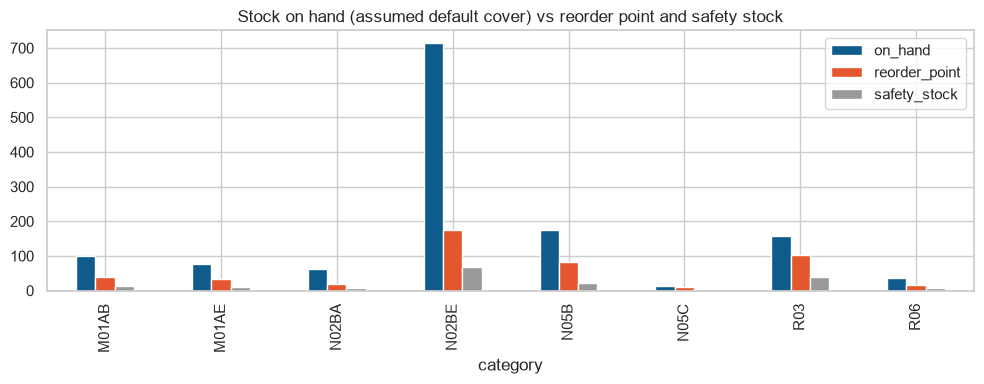

,category,status,days_of_cover,expiry_risk_units,expiry_risk_value
0,M01AB,OK,20.08,0.00,0.00
1,M01AE,OK,20.05,0.00,0.00
2,N02BA,OK,20.03,0.00,0.00
3,N02BE,OK,19.99,0.00,0.00
4,N05B,OK,20.06,0.00,0.00
5,N05C,OK,20.71,0.00,0.00
6,R03,OK,19.99,0.00,0.00
7,R06,OK,19.81,0.00,0.00


In [5]:
p = plans[plans.service_level == cfg["inventory"]["default_service_level"]]
colors = {"OK": "#2E8B57", "REORDER NOW": "#E69F00", "STOCKOUT RISK": "#C0392B", "OVERSTOCK": "#6C5CE7"}
ax = p.set_index("category")[["on_hand", "reorder_point", "safety_stock"]].plot.bar(figsize=(10, 4), color=["#0F5C8C", "#E4572E", "#999"])
ax.set_title("Stock on hand (assumed default cover) vs reorder point and safety stock"); savefig("inv_stock_position")
p[["category", "status", "days_of_cover", "expiry_risk_units", "expiry_risk_value"]]

## 3. What-if: epidemic surge and supplier delay

In [6]:
from src.config import category_assumptions
from src.inventory.whatif import Scenario, simulate

rows = []
for name, sc in {"baseline": Scenario(), "epidemic +30%": Scenario(demand_surge_pct=30),
                 "lead time +4d": Scenario(lead_time_change_days=4), "price -10%": Scenario(price_change_pct=-10),
                 "promo +25%": Scenario(promo_uplift_pct=25)}.items():
    c = "R03"; a = category_assumptions(cfg, c)
    d = float(fb[fb.category == c].sort_values("h").yhat.head(window).mean())
    r = simulate(d, float(best.loc[c, "rmse"]), a["unit_price"], a["unit_cost"], a["lead_time_days"], a["lead_time_sd_days"],
                 0.95, a["order_cost"], cfg["inventory"]["holding_rate_annual"], sc, days=window)
    rows.append({"scenario": name, "demand/day": r.new_demand, "revenue_30d": r.new_revenue_30d,
                 "safety_stock": r.new_plan.safety_stock, "ROP": r.new_plan.reorder_point, "EOQ": r.new_plan.eoq})
pd.DataFrame(rows).set_index("scenario")

,demand/day,revenue_30d,safety_stock,ROP,EOQ
scenario,,,,,
baseline,7.85,"32,981.59",40.01,102.83,382.41
epidemic +30%,10.21,"42,876.06",52.01,133.68,436.01
lead time +4d,7.85,"32,981.59",48.14,142.37,382.41
price -10%,8.32,"31,464.43",42.41,109.00,393.72
promo +25%,9.82,"41,226.98",50.01,128.54,427.55


## 4. Anomalies

In [7]:
an = pd.read_parquet(RES / "anomalies.parquet")
flag = an[an.anomaly]
print(flag.groupby(["category", "direction"]).size().unstack(fill_value=0))
flag.sort_values("z", key=abs, ascending=False)[["date", "category", "actual", "expected", "z", "explanation"]].head(10)

direction  drop  spike
category              
M01AB         0     45
M01AE         1     53
N02BA         0     51
N02BE        28     63
N05B          2     67
N05C          0    120
R03           0     96
R06           0     58


,date,category,actual,expected,z,explanation
9499,2016-12-12,N05B,28.33,1.85,23.53,"Spike: 28.3 units vs 1.9 expected (+1427%, res..."
9152,2015-12-31,N05B,18.00,0.64,21.00,Spike: 18.0 units on a day when only ~0.6 was ...
14519,2019-02-28,R03,35.00,0.00,20.07,Spike: 35.0 units on a day when only ~0.0 was ...
14572,2019-04-22,R03,31.00,0.42,17.53,Spike: 31.0 units on a day when only ~0.4 was ...
4284,2014-03-15,N02BA,11.00,0.37,16.06,Spike: 11.0 units on a day when only ~0.4 was ...
2098,2019-10-01,M01AB,11.34,0.05,15.93,Spike: 11.3 units on a day when only ~0.1 was ...
1939,2019-04-25,M01AB,14.01,1.29,15.83,"Spike: 14.0 units vs 1.3 expected (+989%, resi..."
13998,2017-09-25,R03,26.00,0.00,14.91,Spike: 26.0 units on a day when only ~0.0 was ...
12911,2014-10-04,R03,25.00,0.00,14.33,Spike: 25.0 units on a day when only ~0.0 was ...
16283,2018-03-23,R06,8.50,0.00,13.99,Spike: 8.5 units on a day when only ~0.0 was e...


## 5. Does forecast-driven replenishment help? Back-test on the out-of-sample year
Both policies are periodic-review order-up-to rules with identical lead times and service-level target; only the demand mean/error estimates differ (28-day moving average vs. model forecast with its previous out-of-sample error). Unmet demand is lost.

In [8]:
bt = pd.read_csv(RES / "inventory_backtest.csv")
agg = bt.groupby(["service_level", "policy"]).agg(lost=("lost_units", "sum"), demand=("demand_units", "sum"),
        stockout_days=("stockout_day_share", "mean"), inv_value=("avg_inventory_value", "sum"))
agg["fill_rate_%"] = (1 - agg.lost / agg.demand) * 100
agg["stockout_days_%"] = agg.stockout_days * 100
agg[["fill_rate_%", "stockout_days_%", "lost", "inv_value"]]

fill_rate_%  stockout_days_%   lost  inv_value
service_level policy                                                  
0.90          baseline        95.99             3.50 917.76  23,571.39
              forecast        97.14             3.37 654.82  21,145.96
0.95          baseline        96.77             2.85 740.63  25,611.72
              forecast        98.01             2.34 455.48  23,109.93
0.99          baseline        97.84             1.85 495.15  29,588.49
              forecast        98.95             1.03 239.46  27,310.56

In [9]:
# per-category view at the default service level
bt[bt.service_level == cfg["inventory"]["default_service_level"]].pivot(
    index="category", columns="policy", values=["fill_rate", "avg_inventory"])

fill_rate          avg_inventory         
policy    baseline forecast      baseline forecast
category                                          
M01AB         0.98     0.99         56.13    50.50
M01AE         0.94     0.96         46.50    46.27
N02BA         0.98     0.99         34.78    33.06
N02BE         0.96     0.99        295.95   302.67
N05B          0.99     0.99         90.31    91.72
N05C          0.96     0.98         14.30    10.74
R03           0.97     0.96        133.54   110.89
R06           0.93     0.95         40.05    36.65

In [10]:
import json

print(json.dumps(json.loads((RES / "headline.json").read_text()), indent=2))

{
  "best_model_per_category": {
    "M01AB": "sarimax",
    "M01AE": "sarimax",
    "N02BA": "sarimax",
    "N02BE": "xgboost",
    "N05B": "sarimax",
    "N05C": "sarimax",
    "R03": "sarimax",
    "R06": "sarimax"
  },
  "baseline_model": "snaive",
  "mean_mae_improvement_pct": 26.196918190318634,
  "mean_rmse_improvement_pct": 27.294047637529573,
  "mean_smape_improvement_pct": 16.5795061566341,
  "mean_mape_improvement_pct": 21.880091257989037,
  "mean_best_mape": 75.72384118849229,
  "mean_baseline_mape": 98.4261792258469,
  "mean_best_smape": 66.41215371058811,
  "mean_baseline_smape": 76.46237225971092,
  "backtest_service_level": 0.95,
  "fill_rate_baseline": 0.967678207232992,
  "fill_rate_forecast": 0.980122514817424,
  "stockout_days_baseline": 0.028502747252747252,
  "stockout_days_forecast": 0.023351648351648352,
  "lost_units_baseline": 740.6261599318423,
  "lost_units_forecast": 455.4755247023438,
  "avg_inventory_value_baseline": 25611.71546244017,
  "avg_inventory_va